## Machine Learning Foundations
### 285 College Majors: Can a Machine Learn Which Ones Pay Off?

---

Data: [`ai_salary_majors`](https://github.com/rfordatascience/tidytuesday/tree/main/data/2026/2026-10-20) (TidyTuesday, October 2026). It joins three public sources at the level of the college major: starting salaries from the U.S. Department of Education's [College Scorecard](https://collegescorecard.ed.gov/data/), and AI exposure scores from the [AI Occupational Exposure (AIOE) index](https://github.com/AIOE-Data/AIOE) of Felten, Raj and Seamans, linked through the NCES/BLS major-to-occupation crosswalk. The notebook reads the file straight from GitHub, so there is nothing to upload.

**AI exposure** measures how much the abilities used in a job overlap with what AI can do. High exposure does not mean the job disappears: AI can also assist the work.

**How to use this notebook:**

- **Zoom chat:** post your Predict guesses, Your turn answers and insights in the Zoom chat, so we can compare them as a class.
- **Predict:** before running the next cell, write down your guess. Then run it and compare.
- **Your turn:** a question to answer, usually with code in the empty cell below it. Open **Hint** if you are stuck, and **Answer** only to check your result.
- **Exercise:** homework, to finish after class.

## 1. AI vs. ML vs. Deep Learning and Real-World Applications

Three circles:

| Term | What it means | Example |
|---|---|---|
| **Artificial Intelligence (AI)** | any method that makes a computer do a task we think needs human intelligence. The rules can be written by a person. | a chess program that follows hand-written rules |
| **Machine Learning (ML)** | a part of AI where the computer **learns the rules from data** instead of being told them | a spam filter that learns from emails people marked as spam |
| **Deep Learning (DL)** | a part of ML that uses **neural networks with many layers**, built from many small units like the perceptron we build today | face unlock on your phone, chatbots such as Claude or ChatGPT |

Traditional vs ML

| | Input | Output |
|---|---|---|
| Traditional programming | data + rules | answers |
| Machine learning | data + answers | rules (a **model**) |

**Real-world applications:**

| Application | Type |
|---|---|
| Netflix and Spotify recommendations | ML |
| Credit card fraud alerts | ML |
| Predicting house prices (Zillow estimates) | ML |
| Medical image screening (finding tumors in scans) | DL |
| Speech assistants and translation | DL |
| GPS route finding (shortest path search) | AI, but not ML: it follows a fixed algorithm |

### From Applications to Real Data

Two of the applications in the table above have small versions that come built into Colab: **predicting house prices** (like Zillow estimates) and **reading images** (the idea behind medical image screening).

**What to expect in the California Housing data**
- Each **row** is one neighborhood (a census block group) in California, from the 1990 census.
- The **columns** describe the neighborhood: its location (`longitude`, `latitude`), how old the homes are (`housing_median_age`), its size (`total_rooms`, `population`, `households`) and how wealthy it is (`median_income`, measured in tens of thousands of dollars).
- The last column, `median_house_value`, is the one we usually want to **predict**.

**What to expect in the MNIST data**
- Each **row** is one handwritten digit, drawn as a small 28 x 28 pixel image.
- The image is stored as **784 columns** of numbers (28 x 28 = 784). Each number is how bright one pixel is, from 0 (black) to 255 (white).
- The first column, `label`, tells us which digit (0 to 9) the image shows.

As you look at each dataset, ask yourself: **is there a column that gives us the answer?** This one question will help you tell apart the types of machine learning as mentioned in the previous cell.

## Data:




Colab comes with the two datasets in the `sample_data` folder.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

housing_train = pd.read_csv("/content/sample_data/california_housing_train.csv")
housing_test = pd.read_csv("/content/sample_data/california_housing_test.csv")

print("California Housing: train", housing_train.shape, "| test", housing_test.shape)
print("Each row is one neighborhood (a census block group) in California, 1990 census.")
housing_train.head(10)

California Housing: train (17000, 9) | test (3000, 9)
Each row is one neighborhood (a census block group) in California, 1990 census.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
5,-114.58,33.63,29.0,1387.0,236.0,671.0,239.0,3.3438,74000.0
6,-114.58,33.61,25.0,2907.0,680.0,1841.0,633.0,2.6768,82400.0
7,-114.59,34.83,41.0,812.0,168.0,375.0,158.0,1.7083,48500.0
8,-114.59,33.61,34.0,4789.0,1175.0,3134.0,1056.0,2.1782,58400.0
9,-114.60,34.83,46.0,1497.0,309.0,787.0,271.0,2.1908,48100.0


MNIST: train (20000, 785) | test (10000, 785)
Label: 3
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0 121 248 255 253 253 149   4   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   7  65 145 242 252 242 252 252 252 140   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0 147 252 252 236 158  51  96 193 252 192   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0  10 135 233 2

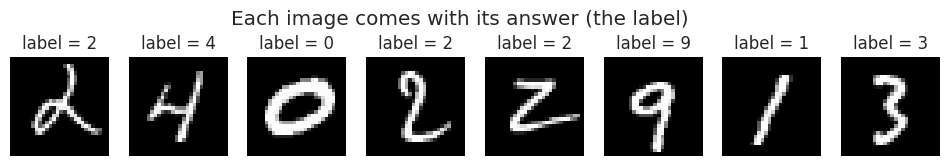

In [ ]:
# The MNIST files have no header: column 0 is the digit, columns 1 to 784 are pixels (28 x 28)
mnist_train = pd.read_csv("/content/sample_data/mnist_train_small.csv", header=None)
mnist_test = pd.read_csv("/content/sample_data/mnist_test.csv", header=None)
mnist_train.columns = ["label"] + [f"px{i}" for i in range(784)]
mnist_test.columns = mnist_train.columns

print("MNIST: train", mnist_train.shape, "| test", mnist_test.shape)

random_pull = mnist_train.sample(1).copy()
label = random_pull.iloc[0, 0]          # row 0, column 0 is the label
pixels = random_pull.iloc[0, 1:].values  # row 0, the other 784 columns are the pixels

print("Label:", label)
for i in range(28):          # 28 rows
    for j in range(28):      # 28 columns in each row
        print(f"{pixels[i * 28 + j]:3d}", end=" ")
    print()                  # move to the next line after each row

mnist_train.head()

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, (_, row) in zip(axes, mnist_train.sample(8).iterrows()):
    ax.imshow(row.drop("label").values.reshape(28, 28), cmap="gray")
    ax.set_title(f"label = {row['label']}")
    ax.axis("off")
plt.suptitle("Each image comes with its answer (the label)")
plt.show()

## 2. Types of Machine Learning: Supervised, Unsupervised and Reinforcement Learning


## 3. Key ML Terminology: Features, Labels, Training Data and Models

| Term | Meaning | In our data |
|---|---|---|
| **Example** (row, observation) | one thing we learn from | one college major |
| **Feature** (input, `X`) | a column the model uses to make a prediction | starting salary, AI exposure |
| **Label** (target, `y`) | the answer we want to predict | salary four years after graduation |
| **Training data** | examples the model **learns** from | about 80% of the majors |
| **Test data** | examples kept aside to **check** the model | the other 20% |
| **Model** | the rule learned from the training data | for example, a straight line |
| **Parameters** | the numbers the model learns | the slope of the line, or a perceptron's weights |
| **Prediction** (`y_hat`) | the model's answer for one example | "this major will earn about \$81,000" |

The columns we use:

| Column | Meaning |
|---|---|
| `field_of_study` | name of the major |
| `broad_field_short` | the family of majors (Engineering, Business, English, ...) |
| `median_starting_salary` | median earnings **one** year after graduation, in US dollars |
| `median_salary_4yr` | median earnings **four** years after graduation |
| `ai_exposure` | AI exposure score: 0 is an average job, above 0 is more exposed than average |
| `ai_exposure_percentile` | the same score as a rank from 0 (least exposed major) to 100 (most exposed) |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE, ORANGE = "#2a78d6", "#eb6834"

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-10-20/ai_salary_majors.csv"
majors_raw = pd.read_csv(URL)
print("Shape:", majors_raw.shape)
majors_raw.head()

Shape: (285, 13)


,cip4,field_of_study,broad_field,broad_field_short,median_starting_salary,median_salary_4yr,ai_exposure,ai_exposure_percentile,ai_exposure_language,ai_exposure_image,n_occupations,n_institutions,n_graduates
0,4604,"Building/Construction Finishing, Management, a...",Construction Trades,Construction Trades,72864,90691.0,-1.201,0.0,-1.133,-0.984,21,4,206
1,5003,Dance,Visual and Performing Arts,Visual & Performing Arts,21878,39716.0,-1.162,0.4,-0.557,-1.796,3,62,1798
2,4807,Woodworking,Precision Production,Precision Production,19151,37055.0,-1.101,0.7,-1.174,-0.750,6,1,24
3,4703,Heavy/Industrial Equipment Maintenance Technol...,Mechanic and Repair Technologies/Technicians,Mechanic & Repair Tech,65331,83528.0,-1.091,1.1,-1.129,-0.746,9,1,25
4,4903,Marine Transportation,Transportation and Materials Moving,Transportation,84187,117176.0,-0.736,1.4,-0.905,-0.139,4,7,632


**Change and rerun:** every row is one major. Type a major into `MAJOR` to see its row. Names must match `field_of_study` exactly.

<details>
  <summary>Hint</summary>
  
  Try "Statistics", "Economics", "Psychology, General" or "Registered Nursing, Nursing Administration, Nursing Research and Clinical Nursing".
  
</details>

In [ ]:
MAJOR = "Computer Science"          # change me
majors_raw.loc[majors_raw["field_of_study"] == MAJOR].T

,200
cip4,1107
field_of_study,Computer Science
broad_field,Computer and Information Sciences and Support ...
broad_field_short,Computer Science
median_starting_salary,70906
median_salary_4yr,100385.0
ai_exposure,1.169
ai_exposure_percentile,70.6
ai_exposure_language,1.168
ai_exposure_image,1.077


## 4. The Machine Learning Workflow: From Data Preparation to Model Evaluation

Almost every ML project follows the same steps:

1. **Define the question.** What do we want to predict, and why?
2. **Prepare the data.** Load it, fix or remove problems (Week 3, EDA).
3. **Explore and choose features.** Which columns could help?
4. **Split** the data into training and test sets.
5. **Train** a model on the training set.
6. **Evaluate** the model on the test set.
7. **Improve and repeat:** try other features or models.

**Our questions:**

- **Regression question:** if we know a major's starting salary, can we predict its salary **four years later**?
- **Classification question:** will a major be a **high earner**, paying at least **\$80,000** four years after graduation?

### Step 2: Prepare the data

A few majors have no four-year salary. That column is our **label**, and a model cannot learn from an example without its answer, so we drop those rows (we do not fill in a label we never observed).

Then we create the yes/no label for the classification question:

`1` means yes,
`0` means no.

In [ ]:
print("Missing four-year salaries:", majors_raw["median_salary_4yr"].isnull().sum())

majors = majors_raw.dropna(subset=["median_salary_4yr"]).copy()
majors["high_earner"] = (majors["median_salary_4yr"] >= 80_000).astype(int)

print("Majors left:", len(majors))
majors["high_earner"].value_counts()

Missing four-year salaries: 8
Majors left: 277


,count
high_earner,
0,198
1,79


### Data Story 1: AI Exposure Does Not Set the Paycheck

Many students worry that a major exposed to AI will pay less. If that were true, AI exposure would be a useful **feature** for predicting salary. Let us check it against the obvious candidate, the starting salary.

**Predict:** which feature will line up more closely with the four-year salary: the starting salary or the AI exposure score? Guess the correlation r for each (recall: r runs from -1 to +1, and 0 means no straight-line link).

**What this cell does:** two scatter plots, one dot per major. High earners are orange. The correlation r is in each title.

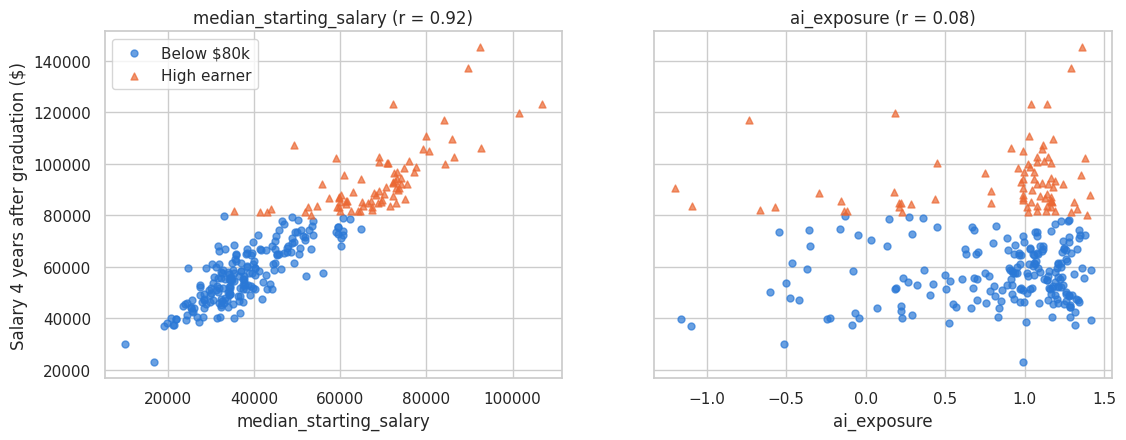

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col in zip(axes, ["median_starting_salary", "ai_exposure"]):
    r = majors[col].corr(majors["median_salary_4yr"])
    for label, color, marker, name in [(0, BLUE, "o", "Below $80k"), (1, ORANGE, "^", "High earner")]:
        part = majors[majors["high_earner"] == label]
        ax.scatter(part[col], part["median_salary_4yr"], s=25, alpha=0.7, color=color, marker=marker, label=name)
    ax.set(title=f"{col} (r = {r:.2f})", xlabel=col)
axes[0].set_ylabel("Salary 4 years after graduation ($)")
axes[0].legend()
plt.show()

**Your turn 3:** which 5 majors have the highest four-year salary? Show their `field_of_study`, `median_salary_4yr` and `ai_exposure`. Are they safe from AI?

<details>
  <summary>Hint</summary>
  
  `majors.nlargest(5, "median_salary_4yr")`, then select the three columns with a list.
  
</details>

<details>
  <summary>Answer</summary>
  
  Operations Research (\$145,296), Mathematics and Computer Science (\$137,218), Biomathematics, Bioinformatics, and Computational Biology (\$123,320), Health Professions Education, Ethics, and Humanities (\$123,202) and Nuclear Engineering Technology/Technician (\$119,783). Four of the five have **above-average** AI exposure (Operations Research is at the 97th percentile). The best-paid majors are not the ones safest from AI.
  
</details>

In [ ]:
# Your turn

**Your turn 4:** how many high earners have **below-average** AI exposure (`ai_exposure < 0`)? Which majors are they?

<details>
  <summary>Hint</summary>
  
  Combine two conditions with `&`, and put each one in brackets: `(majors["high_earner"] == 1) & (majors["ai_exposure"] < 0)`.
  
</details>

<details>
  <summary>Answer</summary>
  
  Only 9 of the 79 high earners have below-average exposure. Most are hands-on technical fields, such as Building/Construction Finishing, Marine Transportation, Vehicle Maintenance and Repair, Fire Protection and Energy Systems Technologies. In contrast, 61% of high earners have an exposure score above 1.
  
</details>

In [ ]:
# Your turn

**Write your insight:** in one sentence, which column would you use as a feature for predicting the four-year salary, and why?

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>
  
  - The starting salary lines up almost perfectly with the four-year salary (r = 0.92), so it is a strong feature.
- AI exposure barely relates to the four-year salary (r = 0.08): highly exposed majors include both the best paid (Operations Research) and some of the lowest paid. On its own it is a weak feature.
- Most high earners are actually **highly** exposed to AI. Only 9 of 79 have below-average exposure, mostly hands-on technical fields.

**From domain knowledge:** the AIOE measures overlap between a job's abilities and what AI can do, not whether the job will be replaced. Many well-paid analytical jobs use AI as a tool.
  
</details>

#### Goal: before training a model, check which features actually relate to the label. A feature that sounds important (AI exposure) can carry almost no information, while a plain one (starting salary) carries a lot.

## 5. Training and Testing Data: Train-Test Split and Why It Matters

Imagine a teacher who gives you the practice questions, and then the final exam uses **exactly the same questions**.

A perfect score would only prove you memorized them. To know whether you really learned, the exam needs **new questions**.

Models are the same. We hide part of the data (the **test set**) while the model learns from the rest (the **training set**). The test score tells us how the model will do on majors it has never seen.

Doing well on new data is called **generalization**.


**Settings in the cell below using the [train_test_split](https://https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html):**

- `test_size=0.2`: 20% of the rows go to the test set.
- `random_state=42`: the split is random, but fixing this number gives everyone the same split.
- `stratify=...`: keep the same share of high earners in both sets.

**Rule:** look at the test set only at the very end, to evaluate. If any information from the test set leaks into training, the score becomes too optimistic. This mistake is called **data leakage**.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42          # change me

train, test = train_test_split(majors, test_size=0.2, random_state=RANDOM_STATE,
                               stratify=majors["high_earner"])

print("Training majors:", len(train), "  Test majors:", len(test))
print(f"Share of high earners  train: {train['high_earner'].mean():.1%}   test: {test['high_earner'].mean():.1%}")

Training majors: 221   Test majors: 56
Share of high earners  train: 28.5%   test: 28.6%


**Change and rerun:** change `RANDOM_STATE` to another number and rerun. The rows in each set change, so the results later in the notebook would also change a little. Set it back to `42` before moving on, so your numbers match the answers.

## 6. Regression vs. Classification Problems

Supervised learning has two kinds of problems, depending on the **label**:

| | Regression | Classification |
|---|---|---|
| The label is | a **number** | a **category** |
| Our question | what will the four-year salary be? | will the major be a high earner (yes/no)? |
| Example output | \$81,454 | 1 (yes) |
| Other examples | house price, temperature tomorrow | spam or not spam, disease or not |
| Measured by | how far off the predictions are | how often the predictions are right |

### Regression: predicting the four-year salary

A **baseline** is the simplest possible model with our best guess being the **average**. Ours ignores every feature and always predicts the training average. Any real model must beat it.

We measure regression with the **Mean Absolute Error (MAE)**: the average size of a miss, in dollars. Smaller is better.

**What this cell does:** we train a **linear regression** model (a straight line) on the training set, then measure both models on the test set. In scikit-learn every model works the same way: create it, `.fit(X, y)` to learn, `.predict(X)` to predict.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X_train = train[["median_starting_salary"]]       # features: a table (double brackets)
y_train = train["median_salary_4yr"]               # label: one column
X_test = test[["median_starting_salary"]]
y_test = test["median_salary_4yr"]

baseline_pred = np.full(len(test), y_train.mean())
line = LinearRegression().fit(X_train, y_train)
line_pred = line.predict(X_test)

print(f"Baseline MAE (always guess the average): ${mean_absolute_error(y_test, baseline_pred):,.0f}")
print(f"Linear regression MAE:                   ${mean_absolute_error(y_test, line_pred):,.0f}")
print(f"Learned line: salary_4yr = {line.coef_[0]:.2f} x starting_salary + {line.intercept_:,.0f}")

Baseline MAE (always guess the average): $15,959
Linear regression MAE:                   $5,564
Learned line: salary_4yr = 1.07 x starting_salary + 17,534


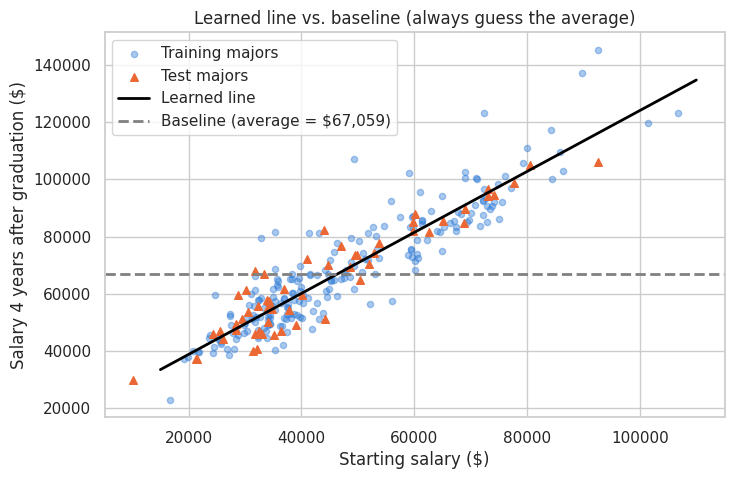

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train["median_starting_salary"], train["median_salary_4yr"], s=20, alpha=0.4, color=BLUE, label="Training majors")
ax.scatter(test["median_starting_salary"], test["median_salary_4yr"], s=30, color=ORANGE, marker="^", label="Test majors")

xs = pd.DataFrame({"median_starting_salary": np.linspace(15_000, 110_000, 100)})
ax.plot(xs, line.predict(xs), color="black", linewidth=2, label="Learned line")
ax.axhline(y_train.mean(), color="gray", linestyle="--", linewidth=2,
           label=f"Baseline (average = ${y_train.mean():,.0f})")

ax.set(title="Learned line vs. baseline (always guess the average)",
       xlabel="Starting salary ($)", ylabel="Salary 4 years after graduation ($)")
ax.legend()
plt.show()

In [ ]:
w = line.coef_[0]
b = line.intercept_

# 1. The mathematical model
print("Learned model:  salary_4yr = w x starting_salary + b")
print(f"  w (slope)     = {w:.4f}")
print(f"  b (intercept) = {b:,.2f}")
print()

Learned model:  salary_4yr = w x starting_salary + b
  w (slope)     = 1.0653
  b (intercept) = 17,533.70



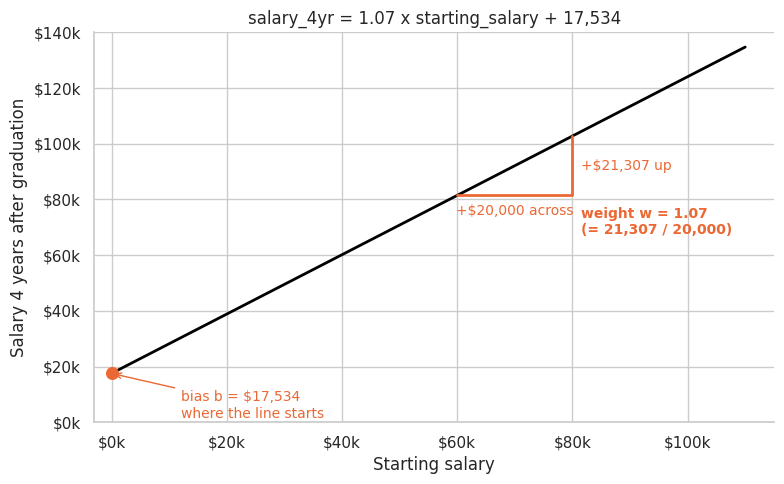

In [ ]:
# @title
from matplotlib.ticker import FuncFormatter

xs = np.linspace(0, 110_000, 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs, w * xs + b, color="black", linewidth=2)

# bias: where the line starts
ax.scatter(0, b, s=70, color=ORANGE, zorder=5)
ax.annotate(f"bias b = ${b:,.0f}\nwhere the line starts", xy=(0, b), xytext=(12_000, 6_000),
            fontsize=10, color=ORANGE, va="center",
            arrowprops=dict(arrowstyle="->", color=ORANGE))

# weight: rise over run triangle
x0, run = 60_000, 20_000
y0, rise = w * x0 + b, w * run
ax.plot([x0, x0 + run, x0 + run], [y0, y0, y0 + rise], color=ORANGE, linewidth=2)
ax.text(x0 + run / 2, y0 - 3_000, f"+${run:,} across", ha="center", va="top", fontsize=10, color=ORANGE)
ax.text(x0 + run + 1_500, y0 + rise / 2, f"+${rise:,.0f} up", va="center", fontsize=10, color=ORANGE)
ax.text(x0 + run + 1_500, y0 - 14_000, f"weight w = {w:.2f}\n(= {rise:,.0f} / {run:,})",
        fontsize=10, color=ORANGE, fontweight="bold")

ax.set(title=f"salary_4yr = {w:.2f} x starting_salary + {b:,.0f}",
       xlabel="Starting salary", ylabel="Salary 4 years after graduation",
       xlim=(-3_000, 115_000), ylim=(0, 140_000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# 2. Pull a few random test majors and do the math by hand
sample = test.sample(3, random_state=42).sort_values("median_starting_salary")

for idx, row in sample.iterrows():
    x = row["median_starting_salary"]
    actual = row["median_salary_4yr"]
    by_hand = w * x + b
    by_sklearn = line.predict(pd.DataFrame({"median_starting_salary": [x]}))[0]
    print(f"Test row {idx}")
    print(f"  {w:.4f} x {x:,.0f} + {b:,.0f} = {by_hand:,.0f}")
    print(f"  line.predict() gives        {by_sklearn:,.0f}   (same number)")
    print(f"  Actual salary               {actual:,.0f}   (error = {actual - by_hand:+,.0f})")
    print()

Test row 168
  1.0653 x 31,748 + 17,534 = 51,356
  line.predict() gives        51,356   (same number)
  Actual salary               46,136   (error = -5,220)

Test row 242
  1.0653 x 32,461 + 17,534 = 52,116
  line.predict() gives        52,116   (same number)
  Actual salary               46,850   (error = -5,266)

Test row 31
  1.0653 x 51,888 + 17,534 = 72,812
  line.predict() gives        72,812   (same number)
  Actual salary               70,554   (error = -2,258)



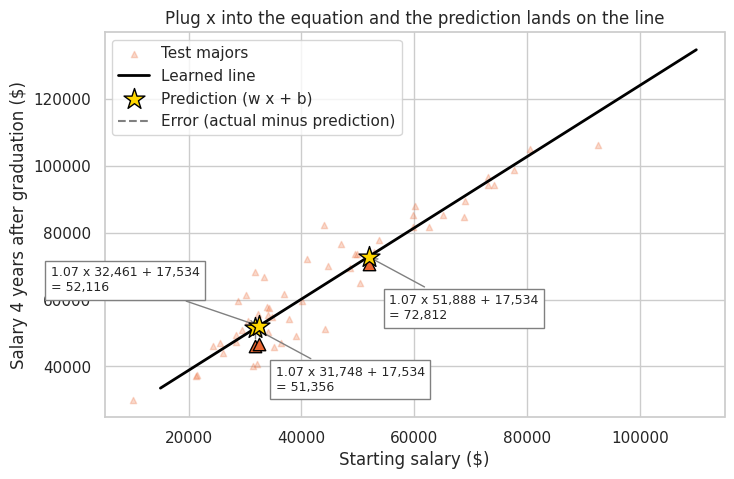

In [ ]:
# 3. Plot: every prediction lands exactly on the line
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(test["median_starting_salary"], test["median_salary_4yr"], s=20, alpha=0.25, color=ORANGE, marker="^", label="Test majors")

xs = pd.DataFrame({"median_starting_salary": np.linspace(15_000, 110_000, 100)})
ax.plot(xs["median_starting_salary"], line.predict(xs), color="black", linewidth=2, label="Learned line")

offsets = [(15, -45), (-150, 25), (15, -45)]
for (idx, row), offset in zip(sample.iterrows(), offsets):
    x = row["median_starting_salary"]
    actual = row["median_salary_4yr"]
    y_hat = w * x + b
    ax.plot([x, x], [actual, y_hat], color="gray", linestyle="--", linewidth=1)          # error
    ax.scatter(x, actual, s=80, color=ORANGE, marker="^", edgecolor="black", zorder=5)  # actual
    ax.scatter(x, y_hat, s=250, color="gold", marker="*", edgecolor="black", zorder=6)  # prediction
    ax.annotate(f"{w:.2f} x {x:,.0f} + {b:,.0f}\n= {y_hat:,.0f}", xy=(x, y_hat),
                xytext=offset, textcoords="offset points", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="gray"),
                arrowprops=dict(arrowstyle="->", color="gray"))

ax.scatter([], [], s=250, color="gold", marker="*", edgecolor="black", label="Prediction (w x + b)")
ax.plot([], [], color="gray", linestyle="--", label="Error (actual minus prediction)")
ax.set(title="Plug x into the equation and the prediction lands on the line",
       xlabel="Starting salary ($)", ylabel="Salary 4 years after graduation ($)")
ax.legend(loc="upper left")
plt.show()

**Reading the line:** the slope is about 1.07, so each extra \$1,000 in starting salary goes with about \$1,070 more four years later. The model learned this number from the data: we never told it.

**Your turn 5:** use the model to predict the four-year salary for a major that starts at \$45,000, and one that starts at \$70,000. Which one does the model call a high earner?

<details>
  <summary>Hint</summary>
  
  `line.predict(pd.DataFrame({"median_starting_salary": [45_000, 70_000]}))`. The model needs a table with the same column name it was trained on.
  
</details>

<details>
  <summary>Answer</summary>
  
  About \$65,474 for a \$45,000 start and about \$92,107 for a \$70,000 start. Only the second is above \$80,000, so only it would count as a high earner.
  
</details>

In [ ]:
# Your turn

### Exercise 1 Regression with Other Features

1. Train a linear regression that uses **only** `ai_exposure` as its feature. Compare its test MAE with the baseline. What does this confirm from Data Story 1?
2. Train one that uses **both** `median_starting_salary` and `ai_exposure`. Does adding AI exposure help?
3. Which test major has the biggest miss with the starting-salary model? Why might that major be hard to predict?

<details>
  <summary>Hints</summary>
  
  1. Copy the regression cell and use `train[["ai_exposure"]]`.
2. Put both names in the list: `train[["median_starting_salary", "ai_exposure"]]`.
3. Compute `(y_test - line_pred).abs()`, add it to a copy of `test` as a new column, and use `nlargest(1, ...)`.
  
</details>

In [ ]:
# Your code here

### What does "degree" mean in the equation?

The degree is the highest power of x in the equation. Each extra power adds one more **weight** for the model to learn:

| Degree | Equation | Number of weights |
|---|---|---|
| 0 | y = w0 | 1 |
| 1 | y = w0 + w1 x | 2 |
| 2 | y = w0 + w1 x + w2 x^2 | 3 |
| 20 | y = w0 + w1 x + w2 x^2 + ... + w20 x^20 | 21 |

Degree 1 is the straight line from earlier: w0 is the bias and w1 is the weight. A higher degree gives the curve more weights to adjust, so it can bend more.

**Predict:** which degree will have the smallest **training** error? Which will have the smallest **test** error?

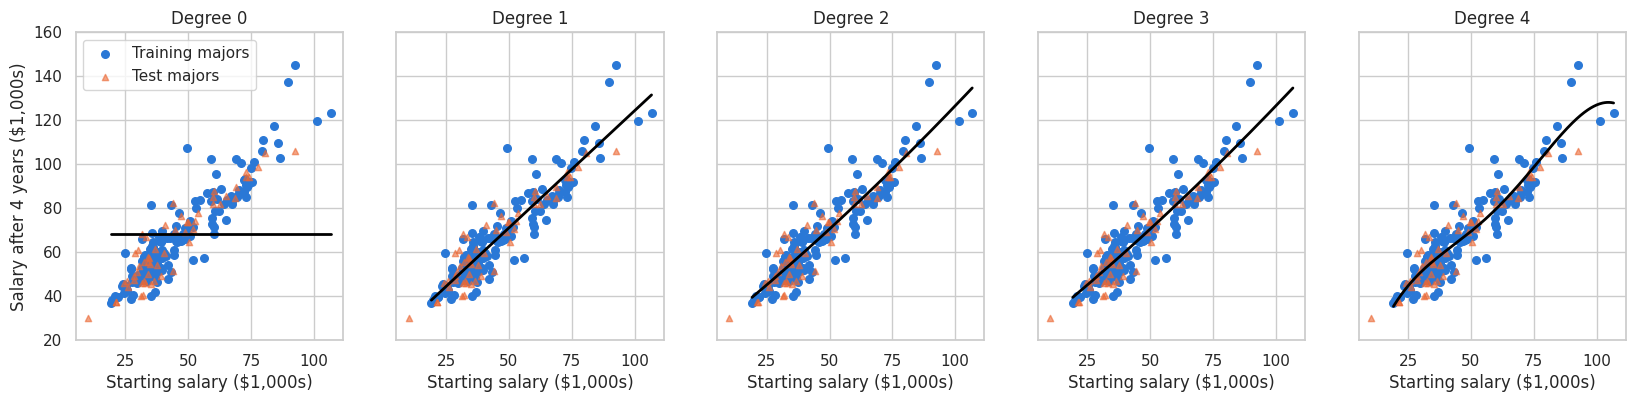

,degree,"train MAE ($1,000s)","test MAE ($1,000s)"
0,0,16.8,16.6
1,1,6.0,5.1
2,2,6.1,5.1
3,3,6.1,5.1
4,4,6.0,5.5


In [ ]:
SAMPLE_SIZE = 150            # change me
DEGREES = [0, 1, 2, 3, 4]        # change me

small = train.sample(SAMPLE_SIZE, random_state=0)
x_small, y_small = small["median_starting_salary"] / 1000, small["median_salary_4yr"] / 1000   # in $1,000s
x_test, y_test_k = test["median_starting_salary"] / 1000, test["median_salary_4yr"] / 1000

fig, axes = plt.subplots(1, len(DEGREES), figsize=(20, 4), sharey=True)
results = []
for ax, degree in zip(axes, DEGREES):
    curve = np.polynomial.Polynomial.fit(x_small, y_small, degree)    # fit a curve of this degree
    results.append({"degree": degree,
                    "train MAE ($1,000s)": mean_absolute_error(y_small, curve(x_small)),
                    "test MAE ($1,000s)": mean_absolute_error(y_test_k, curve(x_test))})
    xs = np.linspace(x_small.min(), x_small.max(), 300)
    ax.scatter(x_small, y_small, color=BLUE, s=30, label="Training majors")
    ax.scatter(x_test, y_test_k, color=ORANGE, marker="^", s=20, alpha=0.6, label="Test majors")
    ax.plot(xs, curve(xs), color="black", linewidth=2)
    ax.set(title=f"Degree {degree}", xlabel="Starting salary ($1,000s)", ylim=(20, 160))
axes[0].set_ylabel("Salary after 4 years ($1,000s)")
axes[0].legend()
plt.show()

pd.DataFrame(results).round(1)

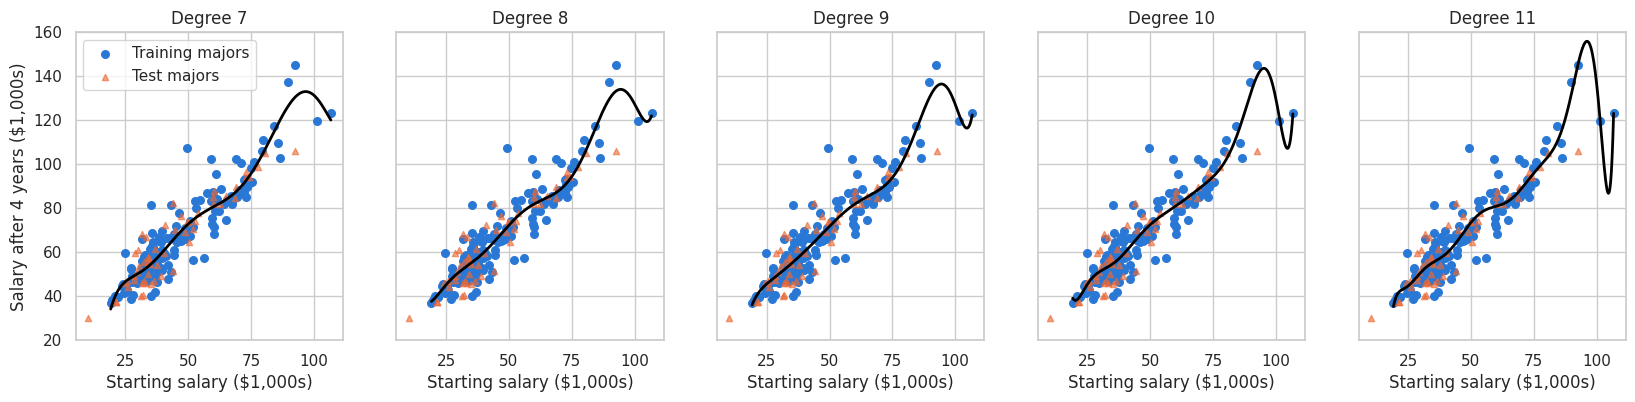

,degree,"train MAE ($1,000s)","test MAE ($1,000s)"
0,7,5.7,7.0
1,8,5.6,6.1
2,9,5.6,7.0
3,10,5.6,12.9
4,11,5.5,21.6


In [ ]:
SAMPLE_SIZE = 150            # change me
DEGREES = [7, 8, 9, 10, 11]        # change me

small = train.sample(SAMPLE_SIZE, random_state=0)
x_small, y_small = small["median_starting_salary"] / 1000, small["median_salary_4yr"] / 1000   # in $1,000s
x_test, y_test_k = test["median_starting_salary"] / 1000, test["median_salary_4yr"] / 1000

fig, axes = plt.subplots(1, len(DEGREES), figsize=(20, 4), sharey=True)
results = []
for ax, degree in zip(axes, DEGREES):
    curve = np.polynomial.Polynomial.fit(x_small, y_small, degree)    # fit a curve of this degree
    results.append({"degree": degree,
                    "train MAE ($1,000s)": mean_absolute_error(y_small, curve(x_small)),
                    "test MAE ($1,000s)": mean_absolute_error(y_test_k, curve(x_test))})
    xs = np.linspace(x_small.min(), x_small.max(), 300)
    ax.scatter(x_small, y_small, color=BLUE, s=30, label="Training majors")
    ax.scatter(x_test, y_test_k, color=ORANGE, marker="^", s=20, alpha=0.6, label="Test majors")
    ax.plot(xs, curve(xs), color="black", linewidth=2)
    ax.set(title=f"Degree {degree}", xlabel="Starting salary ($1,000s)", ylim=(20, 160))
axes[0].set_ylabel("Salary after 4 years ($1,000s)")
axes[0].legend()
plt.show()

pd.DataFrame(results).round(1)

## 7. Overfitting and Underfitting: Understanding Model Generalization

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| The model is | too simple | about right | too complex |
| It learns | not even the main pattern | the main pattern | the pattern **and the noise** |
| Training error | high | low | very low |
| Test error | high | low | high |
| Student analogy | did not study | understood the material | memorized the practice answers |

The warning sign of overfitting is a **big gap**: great on the training set, poor on the test set.

To see this, we give the model a small training set (overfitting is easiest to spot with little data) and fit curves of increasing **degree**:

- degree 0: a flat line (always the average)
- degree 1: a straight line
- degree 10: a very wiggly curve

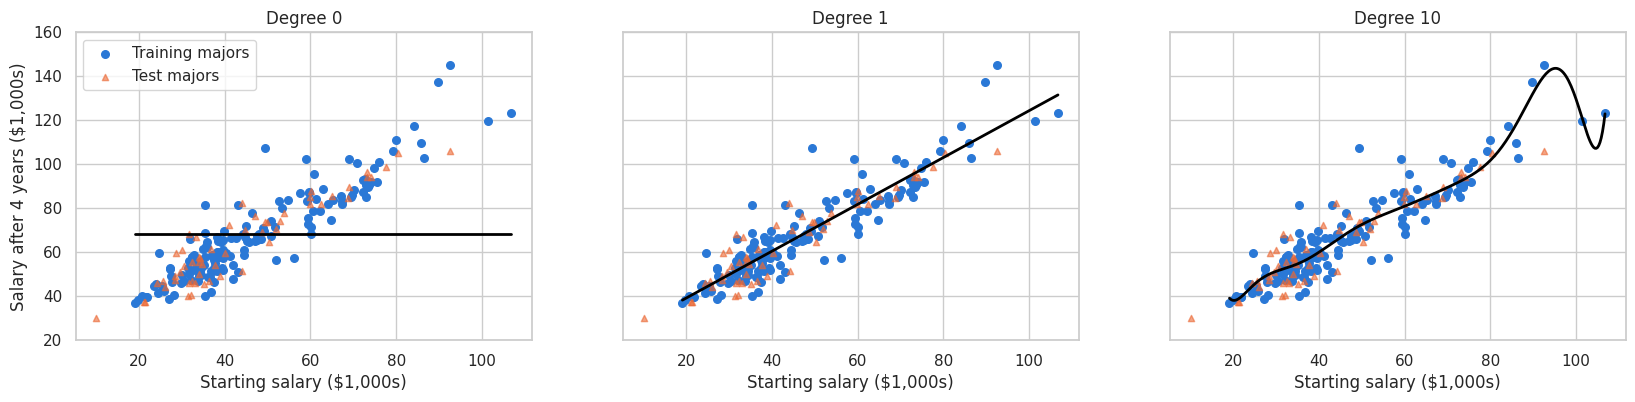

,degree,"train MAE ($1,000s)","test MAE ($1,000s)"
0,0,16.8,16.6
1,1,6.0,5.1
2,10,5.6,12.9


In [ ]:
# @title
SAMPLE_SIZE = 150            # change me
DEGREES = [0, 1, 10]        # change me

small = train.sample(SAMPLE_SIZE, random_state=0)
x_small, y_small = small["median_starting_salary"] / 1000, small["median_salary_4yr"] / 1000   # in $1,000s
x_test, y_test_k = test["median_starting_salary"] / 1000, test["median_salary_4yr"] / 1000

fig, axes = plt.subplots(1, len(DEGREES), figsize=(20, 4), sharey=True)
results = []
for ax, degree in zip(axes, DEGREES):
    curve = np.polynomial.Polynomial.fit(x_small, y_small, degree)    # fit a curve of this degree
    results.append({"degree": degree,
                    "train MAE ($1,000s)": mean_absolute_error(y_small, curve(x_small)),
                    "test MAE ($1,000s)": mean_absolute_error(y_test_k, curve(x_test))})
    xs = np.linspace(x_small.min(), x_small.max(), 300)
    ax.scatter(x_small, y_small, color=BLUE, s=30, label="Training majors")
    ax.scatter(x_test, y_test_k, color=ORANGE, marker="^", s=20, alpha=0.6, label="Test majors")
    ax.plot(xs, curve(xs), color="black", linewidth=2)
    ax.set(title=f"Degree {degree}", xlabel="Starting salary ($1,000s)", ylim=(20, 160))
axes[0].set_ylabel("Salary after 4 years ($1,000s)")
axes[0].legend()
plt.show()

pd.DataFrame(results).round(1)

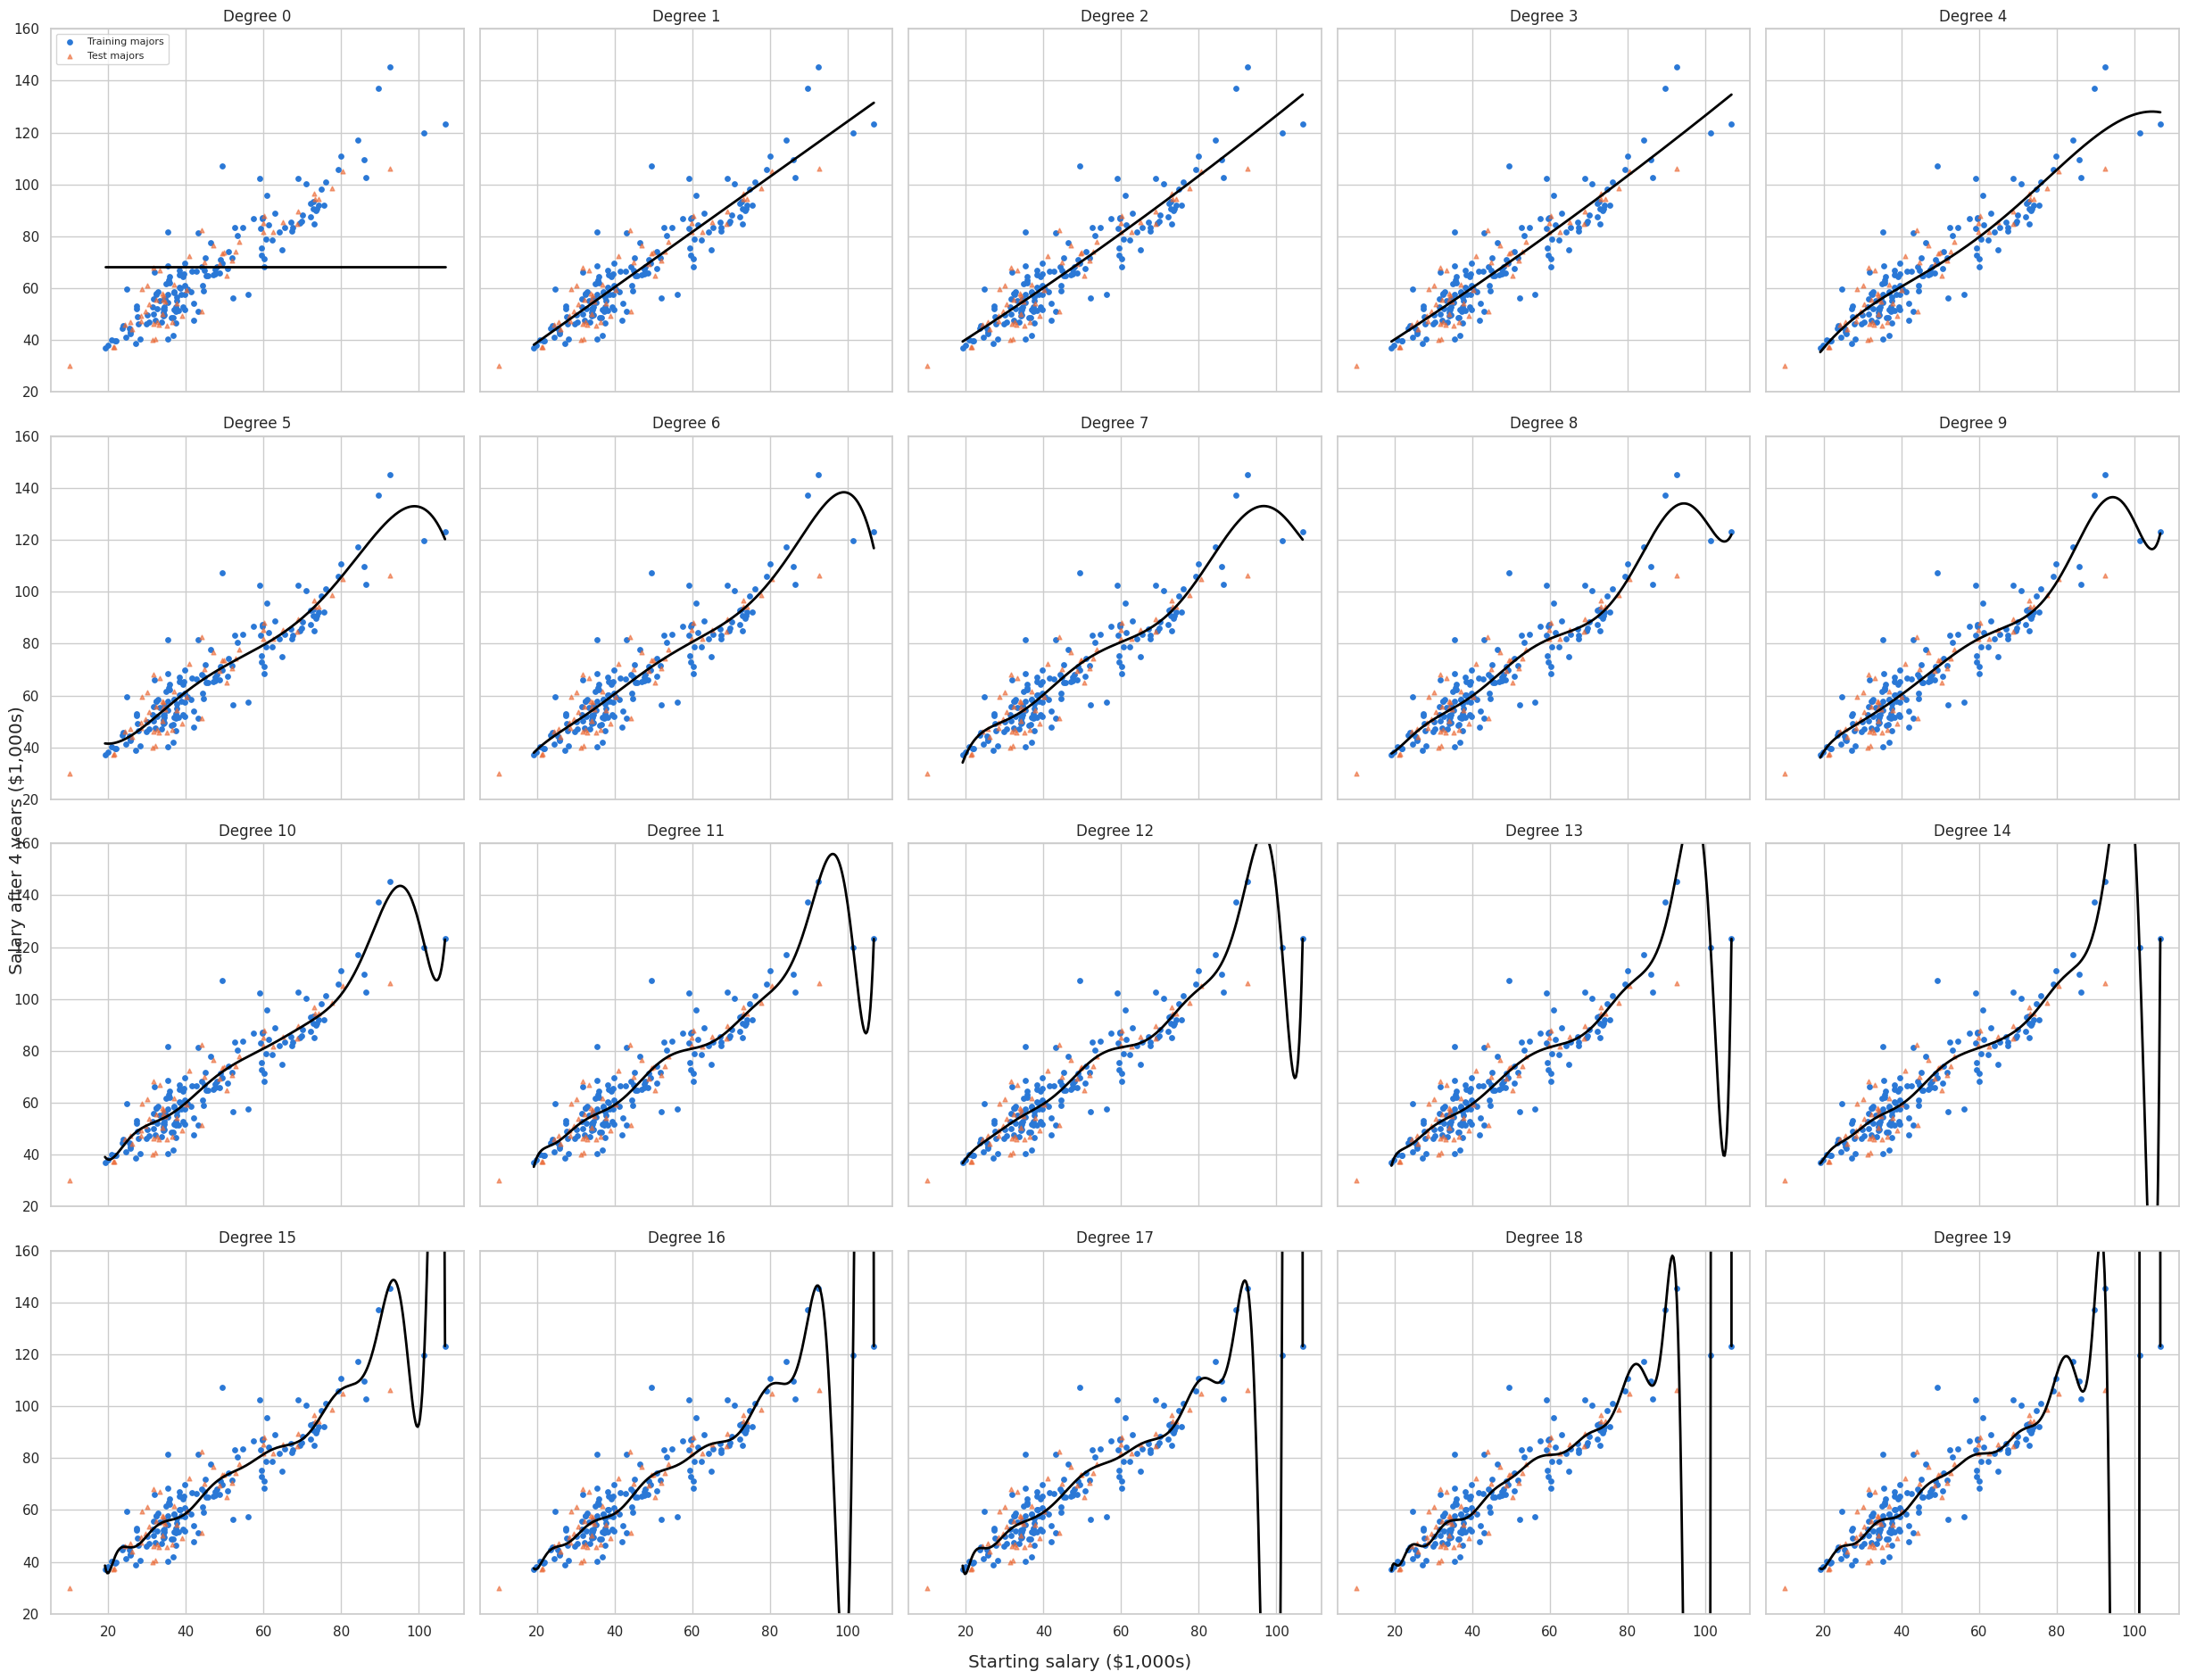

,degree,"train MAE ($1,000s)","test MAE ($1,000s)"
0,0,16.8,16.6
1,1,6.0,5.1
2,2,6.1,5.1
3,3,6.1,5.1
4,4,6.0,5.5
5,5,5.8,5.8
6,6,5.8,5.5
7,7,5.7,7.0
8,8,5.6,6.1
9,9,5.6,7.0


In [ ]:
# @title
xSAMPLE_SIZE = 150                  # change me
DEGREES = list(range(20))          # degrees 0 to 19

small = train.sample(SAMPLE_SIZE, random_state=0)
x_small, y_small = small["median_starting_salary"] / 1000, small["median_salary_4yr"] / 1000    # in $1,000s
x_test, y_test_k = test["median_starting_salary"] / 1000, test["median_salary_4yr"] / 1000

fig, axes = plt.subplots(4, 5, figsize=(25, 19), sharex=True, sharey=True)
axes = axes.flatten()              # turn the 4x5 grid into a flat list of 20 plots
results = []
for ax, degree in zip(axes, DEGREES):
    curve = np.polynomial.Polynomial.fit(x_small, y_small, degree)     # fit a curve of this degree
    results.append({"degree": degree,
                    "train MAE ($1,000s)": mean_absolute_error(y_small, curve(x_small)),
                    "test MAE ($1,000s)": mean_absolute_error(y_test_k, curve(x_test))})
    xs = np.linspace(x_small.min(), x_small.max(), 300)
    ax.scatter(x_small, y_small, color=BLUE, s=15, label="Training majors")
    ax.scatter(x_test, y_test_k, color=ORANGE, marker="^", s=12, alpha=0.6, label="Test majors")
    ax.plot(xs, curve(xs), color="black", linewidth=2)
    ax.set(title=f"Degree {degree}", ylim=(20, 160))

fig.supxlabel("Starting salary ($1,000s)")
fig.supylabel("Salary after 4 years ($1,000s)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(results).round(1)

**Your turn 6:** which degree underfits, which fits well and which overfits? Use the training and test MAE in the table to explain.

<details>
  <summary>Hint</summary>
  
  Look for the model with high error on both sets, and the model with the biggest gap between training and test error.
  
</details>

<details>
  <summary>Answer</summary>
  
  Degree 0 **underfits**: a flat line, with a high error on both sets (20.0 and 16.9 thousand dollars). Degree 1 **fits well**: low error on both (7.0 and 6.7). Degree 10 **overfits**: the lowest training error (4.3) but the test error jumps to 11.8, because the curve bends to pass near every training point, including the noise.
  
</details>

**Your turn 7:** change `SAMPLE_SIZE` to `150` and rerun. What happens to the test error of the degree 10 curve? What does that tell you about one way to reduce overfitting?

<details>
  <summary>Hint</summary>
  
  Compare the degree 10 row before and after. More examples make it harder to memorize every point.
  
</details>

<details>
  <summary>Answer</summary>
  
  With 150 training majors, the degree 10 test error drops from 11.8 to 7.1 thousand dollars, much closer to the straight line (5.6). With more examples, a flexible model cannot bend to every point, so **more data is one way to reduce overfitting**. The straight line is still the best choice here.
  
</details>

**Write your insight:** in one sentence, why can't we judge a model by its training error alone?

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>
  
  - A model can do well on the data it learned from simply by memorizing it, as the degree 10 curve did with 20 majors (training error 4.3, test error 11.8).
- Only the test error tells us how a model **generalizes** to new majors. More data narrows the gap.

**From practice:** data scientists compare training and test scores for every model they build, and pick the simplest model that does well on the test set.
  
</details>

#### Goal: a model should be just complex enough to capture the main pattern. Always compare training and test error: a big gap means overfitting, high error on both means underfitting. More data and simpler models both help reduce overfitting.

## 8. Evaluating Models: Accuracy, Confusion Matrix, Precision and Recall

Now the **classification** question: is a major a high earner (1) or not (0)?

Our first classifier is a rule we write ourselves: **predict "high earner" if the starting salary is above a threshold**. It is a model with one parameter, and we choose that parameter by hand. In Section 11 the perceptron will learn its parameters on its own.

### The confusion matrix

Every prediction falls into one of four boxes:

| | Model says **No** | Model says **Yes** |
|---|---|---|
| **Truly No** | True Negative (TN) | False Positive (FP): a false alarm |
| **Truly Yes** | False Negative (FN): a miss | True Positive (TP) |

From these four counts we get the three main scores:

| Score | Formula | The question it answers |
|---|---|---|
| **Accuracy** | (TP + TN) / all | how often is the model right overall? |
| **Precision** | TP / (TP + FP) | when the model says **yes**, how often is it right? |
| **Recall** | TP / (TP + FN) | of all the real yeses, how many did the model find? |

Accuracy:  0.95
Precision: 0.88
Recall:    0.94


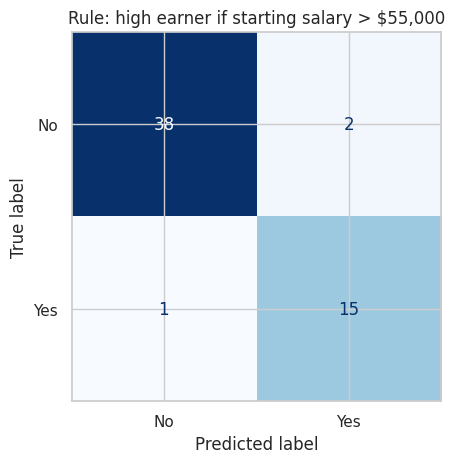

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

THRESHOLD = 55_000          # chosen on the training set (see the table below)

y_true = test["high_earner"]
rule_pred = (test["median_starting_salary"] > THRESHOLD).astype(int)

print(f"Accuracy:  {accuracy_score(y_true, rule_pred):.2f}")
print(f"Precision: {precision_score(y_true, rule_pred):.2f}")
print(f"Recall:    {recall_score(y_true, rule_pred):.2f}")

ConfusionMatrixDisplay(confusion_matrix(y_true, rule_pred), display_labels=["No", "Yes"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Rule: high earner if starting salary > ${THRESHOLD:,}")
plt.show()

**Your turn 8:** read the four boxes of the confusion matrix. How many false alarms and how many misses did the rule make? Check the precision and recall by hand with the formulas.

<details>
  <summary>Hint</summary>
  
  In scikit-learn's chart, rows are the true answer and columns are the prediction. The top-right box is FP, the bottom-left box is FN.
  
</details>

<details>
  <summary>Answer</summary>
  
  2 false alarms (FP) and 1 miss (FN), with 15 true positives and 38 true negatives. Precision = 15 / (15 + 2) = 0.88. Recall = 15 / (15 + 1) = 0.94. Accuracy = (15 + 38) / 56 = 0.95.
  
</details>

### Data Story 2 Accuracy Can Lie

Here is the laziest model possible: **always say "No"**. It never finds a single high earner. How bad can its accuracy be?

**Predict:** write down the accuracy you expect for the lazy model before running the cell.

In [ ]:
lazy_pred = np.zeros(len(test), dtype=int)

print(f"Lazy model accuracy: {accuracy_score(y_true, lazy_pred):.2f}")
print(f"Lazy model recall:   {recall_score(y_true, lazy_pred):.2f}")

Lazy model accuracy: 0.71
Lazy model recall:   0.00


**Accuracy is pretty good(?)**


<details>
  <summary>Why??</summary>
  
  
Only about 29% of the majors are high earners, so saying "No" every time is right about 71% of the time. When one class is much more common than the other (**class imbalance**), accuracy looks good even for a useless model. Recall exposes it: the lazy model finds **0%** of the high earners.
### Choosing the threshold

Where did \$55,000 come from? Choosing a threshold is part of **training**, so we try several thresholds on the **training set** only. Picking it by peeking at test scores would be data leakage. Notice that precision and recall pull against each other.
  
</details>





In [ ]:
rows = []
for t in [40_000, 45_000, 50_000, 55_000, 60_000, 65_000, 70_000]:
    pred = (train["median_starting_salary"] > t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(train["high_earner"], pred),
                 "precision": precision_score(train["high_earner"], pred, zero_division=0),
                 "recall": recall_score(train["high_earner"], pred)})
pd.DataFrame(rows).round(2)

,threshold,accuracy,precision,recall
0,40000,0.76,0.54,0.98
1,45000,0.83,0.63,0.95
2,50000,0.89,0.75,0.94
3,55000,0.92,0.85,0.87
4,60000,0.90,0.90,0.75
5,65000,0.90,1.00,0.63
6,70000,0.84,1.00,0.43


**Your turn 9:** which threshold gives the highest recall, and which gives the highest precision? Suppose a career advisor uses the rule to make a shortlist of high-paying majors for students to explore. Would you rather have high precision or high recall?

<details>
  <summary>Hint</summary>
  
  A low threshold says yes more often. Think about the cost of each mistake: a false alarm adds an extra major to the list; a miss leaves a good major off.
  
</details>

<details>
  <summary>Answer</summary>
  
  On the training set, \$40,000 gives the highest recall (0.98) and \$65,000 or \$70,000 the highest precision (1.00). For a shortlist to explore, **recall** matters more: a false alarm only adds one extra major to look at, but a miss hides a well-paid option. A threshold around \$45,000 to \$50,000 keeps recall near 0.95 while precision stays reasonable.
  
</details>

**Write your insight:** in one sentence, why is accuracy alone not enough to judge a classifier?

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>
  
  - The lazy model scores 71% accuracy without finding a single high earner, because only 29% of majors are high earners.
- Our \$55,000 rule makes only 3 mistakes on the 56 test majors: 2 false alarms and 1 miss (precision 0.88, recall 0.94).
- Moving the threshold trades precision for recall.

**From practice:** in medical screening or fraud detection the positive class is rare, so teams report precision and recall, not just accuracy.
  
</details>

#### Goal: always look at the confusion matrix, not just accuracy. Precision tells you how much to trust a "yes"; recall tells you how many real yeses were found. Which matters more depends on the cost of each mistake, for example missing a disease (low recall) versus a false alarm (low precision).

### Exercise 2 Evaluate a Stricter Label

1. Make a new label `top_earner` for majors paying at least **\$90,000** after four years. What share of majors are top earners?
2. What accuracy would the lazy "always No" model get on this label? Is accuracy more or less misleading than before?
3. Using the **training set**, find the starting-salary threshold that gives the best **recall** while keeping **precision** at 0.6 or higher. Then check that threshold once on the test set.

<details>
  <summary>Hints</summary>
  
  1. Copy the cell that created `high_earner`, change the number, and use `.mean()`.
2. The lazy accuracy equals the share of "No" answers.
3. Add the new column to both `train` and `test` (the same way), copy the threshold table cell, change the label column, and try thresholds from 50,000 to 80,000 in steps of 5,000.
  
</details>

In [ ]:
# Your code here

## 9. Introduction to the Perceptron

In Section 8 **we** chose the rule's threshold. Can the machine find the rule by itself? The simplest learning machine is the **perceptron**, invented by psychologist Frank Rosenblatt in 1958.

It is loosely inspired by a brain cell (a **neuron**): a neuron receives signals from other cells, adds them up, and **fires** only if the total is strong enough.

| Neuron | Perceptron |
|---|---|
| incoming signals | inputs (features) |
| some connections are stronger | weights |
| how easily it fires | bias |
| fires or stays quiet | output 1 or 0 |

A perceptron is a **binary classifier**: it answers yes (1) or no (0). It is also the single building block that deep learning (Section 1) stacks into networks with millions of units.

## 10. How a Perceptron Works: Inputs, Weights, Bias and Activation Function

```
 x1 (starting salary) --- w1 ---\
                                  ( z = w1*x1 + w2*x2 + b ) --> step(z) --> 1 or 0
 x2 (AI exposure)     --- w2 ---/
```

1. **Inputs** `x1, x2`: the features of one example.
2. **Weights** `w1, w2`: how much each input matters. A large positive weight pushes the answer toward yes; a negative weight pushes it toward no.
3. **Bias** `b`: a starting push that makes the perceptron easier or harder to fire, whatever the inputs.
4. **Weighted sum:** `z = w1*x1 + w2*x2 + b`
5. **Activation function:** the **step function** turns `z` into a decision: output **1 if z > 0**, otherwise **0**.

**Geometry:** the points where `z = 0` form a **straight line**. The perceptron says yes on one side of the line and no on the other. This line is called the **decision boundary**.

### Scaling the inputs

Starting salary is in the tens of thousands of dollars;

AI exposure runs from about -1.2 to 1.4.

With raw numbers the salary would drown out the exposure.

<hr>


We **standardize** each feature: subtract the mean and divide by the standard deviation, so 0 means average and 1 means one standard deviation above average. As with any step that learns from data, the scaler is fit on the **training set only**.

In [ ]:
from sklearn.preprocessing import StandardScaler

FEATURES = ["median_starting_salary", "ai_exposure"]

scaler = StandardScaler().fit(train[FEATURES])       # learn the means and standard deviations from training data only
X_train_s = scaler.transform(train[FEATURES])
X_test_s = scaler.transform(test[FEATURES])
y_train_c = train["high_earner"].to_numpy()
y_test_c = test["high_earner"].to_numpy()

pd.DataFrame(X_train_s, columns=FEATURES).describe().round(2).loc[["mean", "std", "min", "max"]]

,median_starting_salary,ai_exposure
mean,-0.00,0.00
std,1.00,1.00
min,-2.10,-3.80
max,3.48,1.15


**What this cell does:** one perceptron decision, computed by hand. We pick weights ourselves for now, and feed in one major.

In [ ]:
MAJOR = "Computer Science"          # change me
w = np.array([1.5, 0.5])            # change me: weights for (starting salary, AI exposure)
b = -0.5                            # change me: bias

row = majors.loc[majors["field_of_study"] == MAJOR]
x = scaler.transform(row[FEATURES])[0]

z = w[0] * x[0] + w[1] * x[1] + b
prediction = 1 if z > 0 else 0

print(f"Scaled inputs: x1 = {x[0]:.2f}, x2 = {x[1]:.2f}")
print(f"z = {w[0]} * {x[0]:.2f} + {w[1]} * {x[1]:.2f} + ({b}) = {z:.2f}")
print("Prediction:", prediction, "   True answer:", int(row["high_earner"].iloc[0]))

Scaled inputs: x1 = 1.41, x2 = 0.67
z = 1.5 * 1.41 + 0.5 * 0.67 + (-0.5) = 1.95
Prediction: 1    True answer: 1


**Your turn 10:** change `MAJOR` to `"Psychology, General"` and rerun. Is the prediction right? Then find a value of `b` that makes the perceptron say **yes** for every major, and explain why.

<details>
  <summary>Hint</summary>
  
  Watch the sign of z. What happens to z if the bias is a very large positive number?
  
</details>

<details>
  <summary>Answer</summary>
  
  Psychology, General has a below-average starting salary (scaled x1 = -0.86), so z = -1.36 and the perceptron says no. That is correct: it pays \$50,152 after four years. Any bias above about 4.5 (try `b = 10`) makes z positive for every major, because the bias outweighs the weighted inputs. The bias sets how easily the perceptron says yes.
  
</details>

## 11. Training a Perceptron: Learning Rule and Weight Updates

Choosing weights by hand does not scale. The perceptron **learns** them with a simple rule. For each training example:

1. Make a prediction `y_hat`.
2. Compute the **error**: `error = y - y_hat`.
3. Update: `w = w + learning_rate * error * x` and `b = b + learning_rate * error`.

The error can only take three values:

| Case | error | What happens |
|---|---|---|
| prediction correct | 0 | nothing changes |
| said **no**, truth is **yes** (a miss) | +1 | weights move **toward** this example, so z goes up next time |
| said **yes**, truth is **no** (a false alarm) | -1 | weights move **away** from this example, so z goes down next time |

- The **learning rate** sets the size of each step.
- One pass through all training examples is called an **epoch**. We repeat for several epochs.

**What this cell does:** one update by hand, starting from all-zero weights, on the first high earner in the training set.

In [ ]:
LEARNING_RATE = 0.1
w, b = np.zeros(2), 0.0

i = np.where(y_train_c == 1)[0][0]             # the first high earner in the training set
x, y = X_train_s[i], y_train_c[i]
z = w @ x + b                                  # @ multiplies matching items and adds them up
y_hat = 1 if z > 0 else 0
error = y - y_hat

print("Major:", train["field_of_study"].iloc[i], "  scaled inputs:", x.round(2))
print(f"z = {z:.2f}  ->  prediction {y_hat},  truth {y},  error {error}")

w = w + LEARNING_RATE * error * x
b = b + LEARNING_RATE * error
print("New weights:", w.round(3), "  New bias:", round(b, 3))

Major: Chemical Engineering   scaled inputs: [1.54 0.46]
z = 0.00  ->  prediction 0,  truth 1,  error 1
New weights: [0.154 0.046]   New bias: 0.1


**Predict:** with all-zero weights, z = 0, so the perceptron says no. This major is a high earner, so that is a miss (error = +1). Will the weights move up or down? Check the output: each new weight is just `0.1 * x`, a small step **toward** this example.

Now we repeat this update for every training major, for many epochs. This function is the **whole perceptron algorithm, written from scratch**: no machine learning library, just a loop and the update rule.

In [ ]:
def train_perceptron(X, y, learning_rate=0.1, epochs=20):
    """Learn perceptron weights and bias with the perceptron learning rule."""
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes_per_epoch = []
    for epoch in range(epochs):
        mistakes = 0
        for x_i, y_i in zip(X, y):
            y_hat = 1 if (w @ x_i + b) > 0 else 0
            error = y_i - y_hat
            w = w + learning_rate * error * x_i
            b = b + learning_rate * error
            mistakes += int(error != 0)
        mistakes_per_epoch.append(mistakes)
    return w, b, mistakes_per_epoch


def predict_perceptron(X, w, b):
    """Step function: 1 if w.x + b > 0, else 0, for every row of X."""
    return (X @ w + b > 0).astype(int)

**Predict:** our data is messy. Will the number of mistakes drop to zero after enough epochs?

Learned weights: [0.214 0.011]   bias: 0.0


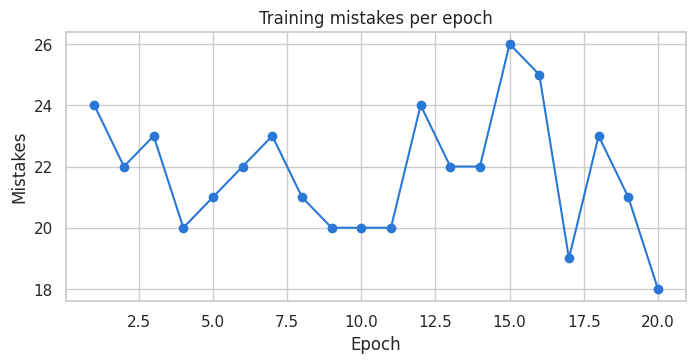

In [ ]:
LEARNING_RATE = 0.1         # change me
EPOCHS = 20                 # change me

w, b, mistakes = train_perceptron(X_train_s, y_train_c, LEARNING_RATE, EPOCHS)

print("Learned weights:", w.round(3), "  bias:", round(b, 3) + 0.0)     # + 0.0 avoids printing -0.0
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, EPOCHS + 1), mistakes, marker="o", color=BLUE)
plt.title("Training mistakes per epoch")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.show()

**What this cell does:** draws the perceptron's decision boundary. The shaded orange side is where it says "high earner". We will reuse this function in Section 12.

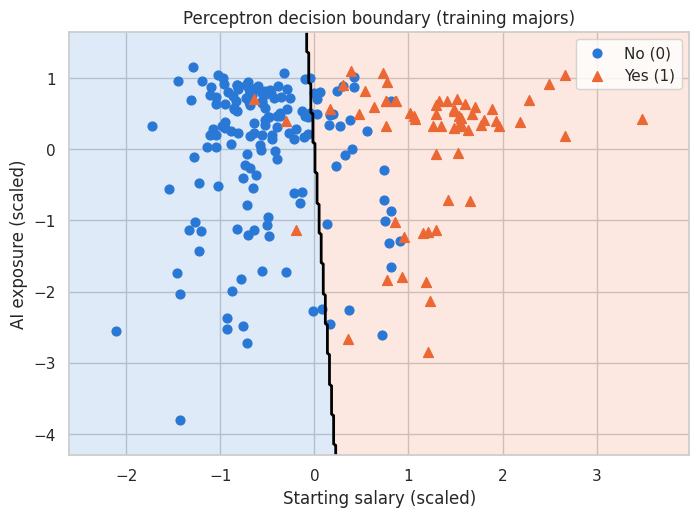

In [ ]:
def plot_boundary(X, y, w, b, ax, title, labels=("x1", "x2"), legend_loc="best"):
    pad = 0.5
    x1_grid, x2_grid = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                                   np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
    zone = predict_perceptron(grid, w, b).reshape(x1_grid.shape)
    ax.contourf(x1_grid, x2_grid, zone, levels=[-0.5, 0.5, 1.5], colors=[BLUE, ORANGE], alpha=0.15)
    ax.contour(x1_grid, x2_grid, zone, levels=[0.5], colors="black", linewidths=2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color=BLUE, marker="o", s=40, label="No (0)")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color=ORANGE, marker="^", s=50, label="Yes (1)")
    ax.set(title=title, xlabel=labels[0], ylabel=labels[1])
    ax.legend(loc=legend_loc)


fig, ax = plt.subplots(figsize=(8, 5.5))
plot_boundary(X_train_s, y_train_c, w, b, ax, "Perceptron decision boundary (training majors)",
              labels=("Starting salary (scaled)", "AI exposure (scaled)"))
plt.show()

**Your turn 11:** look at the learned weights and the boundary. Which feature matters more to the perceptron? Does that agree with Data Story 1?

<details>
  <summary>Hint</summary>
  
  Compare the sizes of `w[0]` (starting salary) and `w[1]` (AI exposure). A boundary that is close to vertical means the decision depends mostly on the horizontal axis.
  
</details>

<details>
  <summary>Answer</summary>
  
  The salary weight (about 0.21) is about 20 times the AI exposure weight (about 0.01). The boundary is almost vertical: the perceptron decides almost entirely by starting salary, at about the average starting salary (\$46,500, scaled value 0). This matches Data Story 1: AI exposure carries little information about pay. The perceptron found this out on its own.
  
</details>

**Change and rerun:** try `LEARNING_RATE = 1.0` and `EPOCHS = 5`, then `EPOCHS = 100`. The boundary moves a bit, but the mistakes never reach 0. Set them back to `0.1` and `20` before moving on.

## 12. Limitations of the Perceptron: Linear Separability and the XOR Problem

A perceptron can only draw **one straight line**. Data is **linearly separable** if one straight line can put all the yes examples on one side and all the no examples on the other. If the data is linearly separable, the perceptron learning rule is guaranteed to find such a line. If not, it keeps making mistakes forever, as we just saw.

The classic test uses three logic gates with two inputs (0 or 1):

| x1 | x2 | AND | OR | XOR ("exactly one") |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 |

**Predict:** which of the three gates can our from-scratch perceptron learn perfectly?

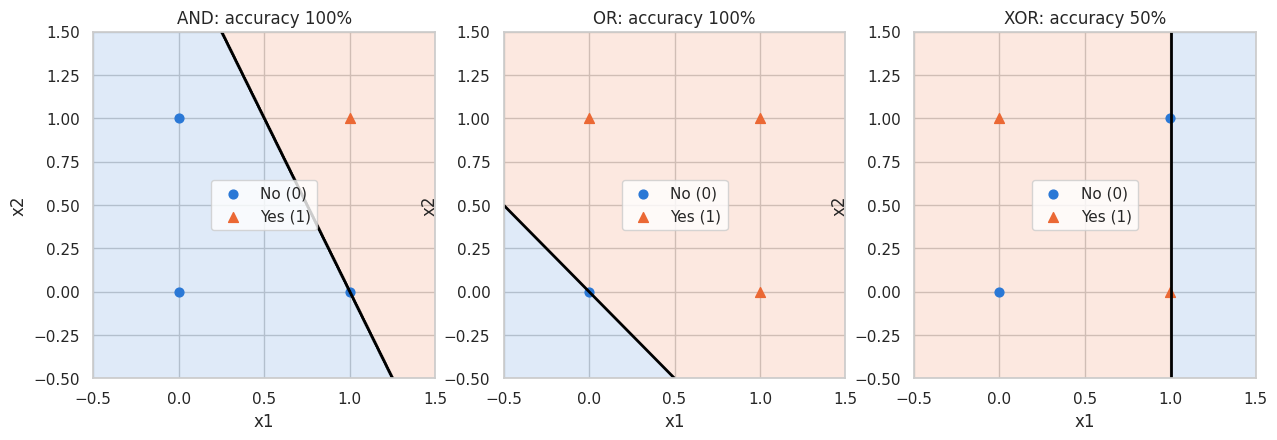

In [ ]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": np.array([0, 0, 0, 1]),
         "OR":  np.array([0, 1, 1, 1]),
         "XOR": np.array([0, 1, 1, 0])}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, y_gate) in zip(axes, gates.items()):
    w_g, b_g, _ = train_perceptron(X_gate, y_gate, learning_rate=0.1, epochs=50)
    acc = (predict_perceptron(X_gate, w_g, b_g) == y_gate).mean()
    plot_boundary(X_gate, y_gate, w_g, b_g, ax, f"{name}: accuracy {acc:.0%}", legend_loc="center")
plt.show()

**Your turn 12:** try to draw, on paper, one straight line that separates the XOR yes points (orange) from the no points (blue). What is the best accuracy any single line can reach on XOR?

<details>
  <summary>Hint</summary>
  
  The two yeses sit on opposite corners, and so do the two no points.
  
</details>

<details>
  <summary>Answer</summary>
  
  No single straight line works: the two yes points sit on opposite corners, and so do the two no points. The best any one line can do is 3 out of 4, or 75%. Our perceptron ended at 50%, because it keeps flipping its line and never settles.
  
</details>

**Look closely:** some points sit exactly on the line. A point on the line has z = 0, which counts as No. The perceptron stops changing as soon as every point is on the correct side, even by a hair: it does not search for the line with the most room.

**Why this matters:** in 1969, Marvin Minsky and Seymour Papert published a book showing that a single perceptron cannot learn XOR. Interest and funding in neural networks dropped for years. The fix is to **stack perceptrons in layers**: one layer draws several lines, and the next layer combines them. That is a **multi-layer perceptron**, the start of **deep learning**. Two lines are enough to solve XOR.

Real data has the same problem: our high earners and other majors overlap, so no single line separates them perfectly.

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn question above</summary>
  
  - AND and OR are linearly separable, so the perceptron learns them perfectly. XOR is not, so it never does.
- Our majors data is not perfectly separable either, so the training mistakes never reached zero in Section 11.

**From history:** the XOR problem slowed neural network research in the 1970s. Multi-layer networks, trained with an algorithm called backpropagation in the 1980s, solved it and led to today's deep learning.
  
</details>

#### Goal: a perceptron can only separate classes with a straight line. It learns AND and OR perfectly but can never learn XOR. Layers of perceptrons remove this limit.

## 13. Building a Perceptron in Python: From Scratch and with Scikit-learn

### From scratch

We already wrote the full algorithm in Section 11: `train_perceptron` and `predict_perceptron`. Now we evaluate it the right way, on the **test set**.

From-scratch perceptron  accuracy 0.82   precision 0.62   recall 0.94


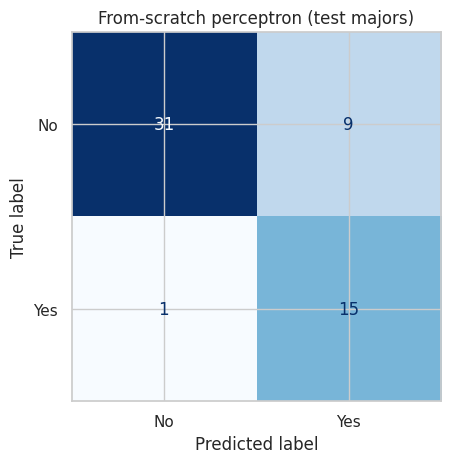

In [ ]:
scratch_pred = predict_perceptron(X_test_s, w, b)

print(f"From-scratch perceptron  accuracy {accuracy_score(y_test_c, scratch_pred):.2f}   "
      f"precision {precision_score(y_test_c, scratch_pred):.2f}   recall {recall_score(y_test_c, scratch_pred):.2f}")

ConfusionMatrixDisplay(confusion_matrix(y_test_c, scratch_pred), display_labels=["No", "Yes"]).plot(cmap="Blues", colorbar=False)
plt.title("From-scratch perceptron (test majors)")
plt.show()

### With scikit-learn

Scikit-learn has a ready-made `Perceptron`. It uses the same learning rule and the same `fit` / `predict` pattern as `LinearRegression`. Two differences: it shuffles the examples each epoch, and it stops early once it stops improving.

- `eta0`: the learning rate
- `max_iter`: the maximum number of epochs
- `coef_` and `intercept_`: the learned weights and bias

In [ ]:
from sklearn.linear_model import Perceptron

sk_perceptron = Perceptron(eta0=0.1, max_iter=20, random_state=42)
sk_perceptron.fit(X_train_s, y_train_c)
sk_pred = sk_perceptron.predict(X_test_s)

print("scikit-learn weights:", sk_perceptron.coef_[0].round(3), "  bias:", sk_perceptron.intercept_.round(3))
print("From-scratch weights:", w.round(3), "  bias:", round(b, 3) + 0.0)

scikit-learn weights: [0.271 0.125]   bias: [-0.1]
From-scratch weights: [0.214 0.011]   bias: 0.0


**What this cell does:** puts all of today's classifiers side by side, scored on the same test majors.

In [ ]:
models = {"Lazy (always No)": lazy_pred,
          f"Hand rule (salary > ${THRESHOLD:,})": rule_pred,
          "Perceptron from scratch": scratch_pred,
          "Perceptron scikit-learn": sk_pred}

pd.DataFrame([{"model": name,
               "accuracy": accuracy_score(y_test_c, pred),
               "precision": precision_score(y_test_c, pred, zero_division=0),
               "recall": recall_score(y_test_c, pred)}
              for name, pred in models.items()]).round(2)

,model,accuracy,precision,recall
0,Lazy (always No),0.71,0.00,0.00
1,"Hand rule (salary > $55,000)",0.95,0.88,0.94
2,Perceptron from scratch,0.82,0.62,0.94
3,Perceptron scikit-learn,0.89,0.81,0.81


**Your turn 13:** the two perceptrons learned different weights. Why? Which model would you pick for the career advisor from Your turn 9, and why?

<details>
  <summary>Hint</summary>
  
  Think about the order in which each version sees the examples. For the advisor, check which model has the best recall without a poor precision.
  
</details>

<details>
  <summary>Answer</summary>
  
  The scikit-learn version shuffles the examples every epoch and stops early, so it sees the examples in a different order. When the data is not separable, the final line depends on the last few updates, so the two versions end in different places.

Our hand rule wins (accuracy 0.95, precision 0.88, recall 0.94). The from-scratch perceptron ended with its line at the average starting salary (about \$46,500), lower than our \$55,000, so it finds the high earners (recall 0.94) but raises 9 false alarms (precision 0.62). For the advisor, the hand rule is the best choice. The lesson: a learned model is not automatically better than a simple, well-chosen rule, and a single perceptron keeps the **last** line it reaches, not the best one.
  
</details>

### Exercise 3 Perceptron Experiments

1. Add a third feature, `ai_exposure_image`, to `FEATURES`. Rerun the scaling cell and train the from-scratch perceptron. Does test recall improve?
2. Train the from-scratch perceptron on the **NAND** gate (the opposite of AND: outputs 0, 0 -> 1, 0, 1 -> 1, 1, 0 -> 1, 1, 1 -> 0). Can it learn it? Explain using linear separability.
3. Train the scikit-learn perceptron with `random_state` set to 0, 1, 2, 3 and 4. How much does the test accuracy change? What does this tell you about trusting one run?

<details>
  <summary>Hints</summary>
  
  1. `FEATURES = ["median_starting_salary", "ai_exposure", "ai_exposure_image"]`. The functions work for any number of features, but `plot_boundary` only draws two.
2. Copy the gates cell and add `"NAND": np.array([1, 1, 1, 0])`. Plot the four points first and check whether one line separates them.
3. Use a `for` loop over the seeds and print `accuracy_score` each time.
  
</details>

In [ ]:
# Your code here

## Summary

| Topic | Key idea |
|---|---|
| AI, ML, DL | ML learns rules from data; deep learning stacks many perceptron-like units in layers |
| Types of ML | supervised (with answers), unsupervised (no answers), reinforcement (rewards) |
| Features and labels | features `X` go in, the label `y` is what we predict |
| Train-test split | judge a model only on data it has not seen |
| Regression vs. classification | predict a number vs. predict a category |
| Overfitting | great on training data, poor on test data |
| Evaluation | accuracy can lie with imbalanced classes; check precision and recall |
| Perceptron | weighted sum + bias + step function = one straight decision boundary |
| Learning rule | `w = w + learning_rate * (y - y_hat) * x`, repeated over epochs |
| XOR | one line cannot solve it; layers of perceptrons can |

**From our data:** the starting salary predicts the four-year salary well (r = 0.92), while AI exposure barely relates to it (r = 0.08). A perceptron learns this on its own: it puts most of its weight on the starting salary.

**Limitation:** each row is the **median** of a whole major, not one person. The model says nothing about how much an individual student will earn.

### Exercise 4 Write a Model Card

A **model card** is a short summary that a company publishes with a model. Write one for your best classifier from today from the dataset enstating:

1. What it predicts, and which features it uses.
2. Its test accuracy, precision and recall, and what each means in plain words.
3. One kind of mistake it makes, using a real major from the test set as an example. (Please code this)
4. One limitation of the data or the model, and who should **not** use it. (Linking any metrics - Acc, Prec or Recall)

<details>
  <summary>Hints</summary>
  
  For item 3, add the predictions to a copy of `test` and filter the rows where the prediction and `high_earner` disagree. For item 4, think about medians versus individual students, and about the fact that the label threshold of \$80,000 was our own choice.
  
</details>

In [ ]:
# Your code here